# 🧪 LAB: Manual MLPs for Classification and Regression

In this lab, you will use `PyTorch` to implement manually a multi-layer perceptron (MLP) for three different tasks: binary classification, multi-class classification and regression. 

## General instructions to complete in ALL three tasks:

1. ***IMPLEMENTATION***:
   
Implement a separate class for each task:

  - `BinaryMLP` for the binary classification task  
  - `MultiClassMLP` for the multi-class classification task  
  - `RegressionMLP` for the regression task

   Each class must include the following methods:

  - `__init__` for initializing 1 or 2 hidden layers. (*Help*: having a second hidden layer only means the need of having a extra set of weights and intercept). 
  - `forward` to transfer information from the input to the output layer. (*Help*: make sure that information passes through a second hidden layer if there is one).
  - `cost` computing the cost.
  - `fit` for training, using the gradients to manually update the parameters of the model. **Use stochastic gradient descent to update your weights**. *N.B.* You may probably reuse much of the code we used in this week tutorial already. 
  - `predict` to convert the information at the output layer into the required output.

2. ***DATA PREPARATION***

For each task, you will be provided with a toy dataset. For each dataset:

  - Split into training and holdout sets (use an 80/20 split)
  - Standardize the features properly, avoiding data leakage
  - Convert all data into `PyTorch` Tensors for compatibility

3. ***MODEL TRAINING AND EVALUATION***

Instantiate the model for each task and train it under different hyperparameter configurations. In each case, record the performance on **both** the training and holdout sets using the appropriate metric for the task (accuracy, MSE, etc.). You should explore the following configurations:

  - One hidden layer, varying the number of hidden units (use ReLU as their activation function)
  - Same number of hidden units across one or two hidden layers (use ReLU as their activation function)
  - Repeat the above setups using Tanh activation instead of ReLU

Present your results in a compact way (e.g., a summary table, a data frame etc).

**NOTE**: When training your model, use a fixed learning rate of your choice (e.g., 0.01 is a reasonable starting point) and a reasonably large number of  epochs (e.g., 100–200) based on how training and holdout performance evolve.

4. ***REFLECTION AND DISCUSSION***

Reflect on the impact of the different hyperparameter settings:

- How does the number of hidden units affect performance?
- What changes when using two layers instead of one?
- How does the activation function (ReLU vs. Tanh) influence results?

Please elaborate your answers.

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

**Ideally, each group member should be responsible for one of the separate tasks.** BUT, everyone should help each other along the way, both reviewing and refining results and discussion.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Kaitlin Luu, Natalie Schweickert, James Torgerson"

## 1. Pre-implementation Group Discussion (15 points)

Discuss and agree on:

- What cost function should be used for each of the below tasks.

For BinaryMLP the cost function is Binary Cross-Entropy. For MulticlassMLP the cost function is Categorical Cross-Entropy. For RegressionMLP the cost function is Mean Squared Error.

- What changes are needed in the output layer for each of these tasks. In particular, consider the number of units and the activation function.

For BinaryMLP there is 1 output unit with a sigmoid activation. For MulticlassMLP there is 1 output unit per class (so $l$ units for $l$ classes) with a softmax activation. For RegressionMLP there is 1 output unit with a linear (identity) activation, since the prediction is just the weighted sum of the inputs plus the bias.

- Why it is important to standardize the data before training each model.

It is important to standardize the data before training each model because features on different scales will produce uneven gradients. For instance, the model may have a much larger impact on features with large values compared to features with small values. Therefore, training would be ineffective if we used a single learning rate on all of the data. Making the mean 0 and standard deviation 1 also ensures that the random weight initialization for the model works since it assumes that everything is of similar scale. Additionally, standardizing keeps the numbers in a range where RelU and Tanh work properly. This ensures that the differences in the results for reflect the difference in activation function rather a difference than scaling.

- How you could detect overfitting when training your models.

Primarily, the way we detect overfitting is by comparing how our model performs on training data versus our test/holdout data. If our model performs well on the former but not on the latter, then we know our model is overfitting. For MLP and other neural network models, we can also compare our training loss versus our test loss. As we train our data, if our training loss continues to decrease while our test loss plateaus, then we are overfitting. Lastly, we can look at our model to see if we are likely overfitting - if we have a large number of parameters relative to our number of observations, then we are likely overfitting.

## 2. Binary Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [ ]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 3. Multi-Class Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

---
**NOTE**: This will likely be the most challenging exercise. To help you, here are some pointers:

 - The **output (last) layer** should have as many units as there are classes in your data.  

 - The **activation function of the output layer must be softmax**, not sigmoid. Softmax ensures that all output values are between 0 and 1 and sum to 1, so they can be interpreted as probabilities across the different classes. (*Help*: you may want to look into `torch.nn.functional` to find its implementation...)

 - For a multi-class problem, your target variable `y` should be **one-hot encoded**. For example:  
   - Label = 0 → [1, 0, 0]  
   - Label = 1 → [0, 1, 0]  
   - Label = 2 → [0, 0, 1]  
   You can easily achieve this with `OneHotEncoder` from `sklearn.preprocessing`.  

 - The **predicted class** corresponds to the unit with the highest probability.  
   Example:  
   - `[0.1, 0.3, 0.6] → class 2`  
   - `[0.6, 0.2, 0.2] → class 0`  

 - For this exercise, you need to **implement the categorical cross-entropy loss** (an extension of binary cross-entropy to multiple classes). It is defined as:  

   $$-\sum_{c=1}^{l} y_{o,c}\,\log(p_{o,c}),$$

   where $l$ is the number of classes, $y_{o,c}$ is the one-hot encoded label for observation $o$, and $p_{o,c}$ is the predicted probability for class $c$ (after applying softmax). The log is the natural logarithm.

---

In [2]:
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000, n_classes=3, 
                           n_clusters_per_class=1, 
                           n_features=2, n_informative=2, n_redundant=0, random_state=1234, flip_y=0.15)

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 4: Regression Task (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [7]:
from sklearn.datasets import make_regression
X, y = make_regression(n_samples=1000, n_features=2, n_informative=2, random_state=1234, noise=75)

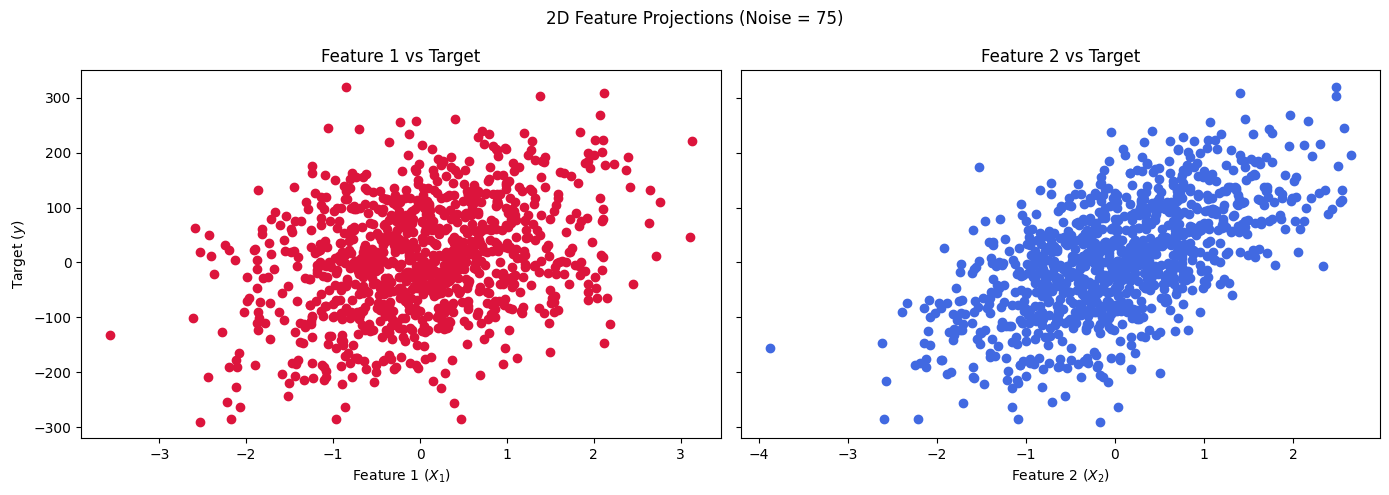

In [ ]:
# basic data vis so i can see how the data looks like
import matplotlib.pyplot as plt
import seaborn as sns

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# feature 1 v targer
ax1.scatter(X[:, 0], y, color="crimson")
ax1.set_xlabel("Feature 1 ($X_1$)")
ax1.set_ylabel("Target ($y$)")
ax1.set_title("Feature 1 vs Target")

# feature 2 v target
ax2.scatter(X[:, 1], y, color="royalblue")
ax2.set_xlabel("Feature 2 ($X_2$)")
ax2.set_title("Feature 2 vs Target")

plt.suptitle("2D regression task data")
plt.tight_layout()
plt.show()

In [ ]:
# 1 - Implementation - Regression Task
import torch

class RegressionMLP(object):

    def __init__(self, input_dim, hidden_dim1, hidden_dim2=None, learning_rate=0.001, activation=torch.relu):

        self.learning_rate = learning_rate
        self.hidden_dim2 = hidden_dim2 
        self.activation = activation # so we can perform model training/evaluation on tanh v. relu

        # 1 hidden layer option
        if hidden_dim2 == None:
            self.W_1 = torch.randn(input_dim, hidden_dim1, requires_grad=True)
            self.b_1 = torch.randn(hidden_dim1, requires_grad=True)
            self.W_2 = torch.randn(hidden_dim1, 1, requires_grad=True)
            self.b_2 = torch.randn(1, requires_grad=True)

        # 2 hidden layer option
        else:
            self.W_1 = torch.randn(input_dim, hidden_dim1, requires_grad=True)
            self.b_1 = torch.randn(hidden_dim1, requires_grad=True)
            self.W_2 = torch.randn(hidden_dim1, hidden_dim2, requires_grad=True)
            self.b_2 = torch.randn(hidden_dim2, requires_grad=True)
            self.W_3 = torch.randn(hidden_dim2, 1, requires_grad=True)
            self.b_3 = torch.randn(1, requires_grad=True)

    def forward(self, X):

        # 1 hidden layer option
        if self.hidden_dim2 == None:
            h = self.activation(torch.matmul(X, self.W_1) + self.b_1) # implements activation(X @ W_1 + b1) --> linear regression 
            out = torch.matmul(h, self.W_2) + self.b_2 # implements h @ W_2 + b2

        # 2 hidden layer option
        else:
            h1 = self.activation(torch.matmul(X, self.W_1) + self.b_1) # implements activation(X @ W_1 + b1) 
            h2 = self.activation(torch.matmul(h1, self.W_2) + self.b_2) # implements activation(h1 @ W_2 +b2)
            out = torch.matmul(h2, self.W_3) + self.b_3 # implements h @ W_3 + b3
            
        return out

    def cost(self, y_pred, y_true):
        # cost function for linear regression is MSE
        return ((y_pred - y_true) ** 2).mean()

    def fit(self, X, y, n_epochs=100):

        for epoch in range(n_epochs):

            randomperm = torch.randperm(X.shape[0])

            for ii in randomperm:
               x_batch, y_batch = X[ii], y[ii]

               # forward
               y_pred = self.forward(x_batch)

               # cost
               loss = self.cost(y_pred, y_batch)
               
               # Backward pass 
               loss.backward()

               with torch.no_grad():
                self.W_1 -= self.learning_rate * self.W_1.grad
                self.b_1 -= self.learning_rate * self.b_1.grad
                self.W_2 -= self.learning_rate * self.W_2.grad
                self.b_2 -= self.learning_rate * self.b_2.grad
                if self.hidden_dim2 is not None: # in case of 2 hidden layers
                    self.W_3 -= self.learning_rate * self.W_3.grad
                    self.b_3 -= self.learning_rate * self.b_3.grad
                           
                # Zero gradients
                self.W_1.grad.zero_()
                self.b_1.grad.zero_()
                self.W_2.grad.zero_()
                self.b_2.grad.zero_()
                if self.hidden_dim2 is not None: # in case of 2 hidden layers
                    self.W_3.grad.zero_()
                    self.b_3.grad.zero_()

            # print cost every 10 epochs (a la what we implemented in class notes)
            if epoch % 10 == 0:
                print(f"Epoch {epoch}, Cost: {loss.item():.4f}")
        return self 

    def predict(self, X):
        with torch.no_grad():
            return self.forward(X)

In [ ]:
# 2 - Data Preparation - Regression Task

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## split into training data and holdout
X_train, X_holdout, y_train, y_holdout = train_test_split(X, y, test_size=0.2, random_state=1234)

## standardize 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_holdout_scaled = scaler.transform(X_holdout) # standardize according to scaler fit to training data

### also standardizing y b/c 

# convert to tensor
X_train = torch.from_numpy(X_train_scaled).float()
X_holdout = torch.from_numpy(X_holdout_scaled).float()

y_train = torch.from_numpy(y_train).float()
y_holdout = torch.from_numpy(y_holdout).float()

In [ ]:
import pandas as pd
import torch

# Define the hyperparameter configurations to explore
configurations = [
    # 1 Hidden Layer with ReLU w/ varied number of hidden units
    {"hidden_dim1": 8, "hidden_dim2": None, "activation": torch.relu, "name": "1 Layer (8 units, ReLU)"},
    {"hidden_dim1": 16, "hidden_dim2": None, "activation": torch.relu, "name": "1 Layer (16 units, ReLU)"},
    {"hidden_dim1": 32, "hidden_dim2": None, "activation": torch.relu, "name": "1 Layer (32 units, ReLU)"},
    
    # 2 Hidden Layers w/ ReLU (to compare against 1 Layer (16 units, ReLU)
    {"hidden_dim1": 16, "hidden_dim2": 16, "activation": torch.relu, "name": "2 Layers (16*16 units, ReLU)"},
    
    # Repeat all w/ Tanh Activation
    {"hidden_dim1": 8, "hidden_dim2": None, "activation": torch.tanh, "name": "1 Layer (8 units, Tanh)"},
    {"hidden_dim1": 16, "hidden_dim2": None, "activation": torch.tanh, "name": "1 Layer (16 units, Tanh)"},
    {"hidden_dim1": 32, "hidden_dim2": None, "activation": torch.tanh, "name": "1 Layer (32 units, Tanh)"},
    {"hidden_dim1": 16, "hidden_dim2": 16, "activation": torch.tanh, "name": "2 Layers (16*16 units, Tanh)"},
]

results = [] # empty so we can append for loop data into it

for config in configurations:
    print(f"--- Training: {config['name']} ---") # added '---' on either end so it was easier to delineate
    
    # instantiate the model
    model = RegressionMLP(
        input_dim=X_train.shape[1],
        hidden_dim1=config["hidden_dim1"],
        hidden_dim2=config["hidden_dim2"],
        learning_rate=0.001,
        activation=config["activation"]
    )
    
    # train model
    model.fit(X_train, y_train, n_epochs=100)
    
    # record performance (MSE) on both train and test set
    train_preds = model.predict(X_train)
    holdout_preds = model.predict(X_holdout)
    
    train_mse = model.cost(train_preds, y_train).item()
    holdout_mse = model.cost(holdout_preds, y_holdout).item()
    
    # 4. Store results
    results.append({
        "Configuration": config["name"], # to tell configurations apart
        "Hidden Dim 1": config["hidden_dim1"],
        "Hidden Dim 2": str(config["hidden_dim2"]), # string b/c of None
        "Activation": "ReLU" if config["activation"] == torch.relu else "Tanh",
        "Train MSE": ro
        und(train_mse, 4),
        "Holdout MSE": round(holdout_mse, 4)
    })

--- Training: 1 Layer (8 units, ReLU) ---
Epoch 0, Cost: 4610.4321
Epoch 10, Cost: 3884.8308
Epoch 20, Cost: 10446.5391
Epoch 30, Cost: 577.1530
Epoch 40, Cost: 2149.6770
Epoch 50, Cost: 2384.7483
Epoch 60, Cost: 3528.8733
Epoch 70, Cost: 579.1917
Epoch 80, Cost: 16326.6074
Epoch 90, Cost: 272.9752
--- Training: 1 Layer (16 units, ReLU) ---
Epoch 0, Cost: 16370.6729
Epoch 10, Cost: 15506.2686
Epoch 20, Cost: 3034.9976
Epoch 30, Cost: 2681.4175
Epoch 40, Cost: 134.8174
Epoch 50, Cost: 987.0873
Epoch 60, Cost: 494.7191
Epoch 70, Cost: 1188.3214
Epoch 80, Cost: 10.4268
Epoch 90, Cost: 7418.6592
--- Training: 1 Layer (32 units, ReLU) ---
Epoch 0, Cost: 4685.5317
Epoch 10, Cost: 1600.0836
Epoch 20, Cost: 18775.3438
Epoch 30, Cost: 6466.6484
Epoch 40, Cost: 14364.7373
Epoch 50, Cost: 717.0666
Epoch 60, Cost: 21.3440
Epoch 70, Cost: 6040.9429
Epoch 80, Cost: 24441.5078
Epoch 90, Cost: 6379.6685
--- Training: 2 Layers (16*16 units, ReLU) ---
Epoch 0, Cost: nan
Epoch 10, Cost: nan
Epoch 20, Cos

In [15]:
# Create a compact summary DataFrame
summary_df = pd.DataFrame(results)
print("\n")
print(summary_df.to_string(index=False))



               Configuration  Hidden Dim 1 Hidden Dim 2 Activation  Train MSE  Holdout MSE
     1 Layer (8 units, ReLU)             8         None       ReLU 10833.8594   10971.8525
    1 Layer (16 units, ReLU)            16         None       ReLU 10833.2930   10979.2412
    1 Layer (32 units, ReLU)            32         None       ReLU 10833.8438   10989.3027
2 Layers (16*16 units, ReLU)            16           16       ReLU        NaN          NaN
     1 Layer (8 units, Tanh)             8         None       Tanh 15859.8594   17199.6641
    1 Layer (16 units, Tanh)            16         None       Tanh 16019.2236   17418.6230
    1 Layer (32 units, Tanh)            32         None       Tanh 17213.8359   19383.2422
2 Layers (16*16 units, Tanh)            16           16       Tanh 13414.8232   13482.7363


## 5. Discussion (5 points)

You created a separate class for each task and likely repeated much of the same code across implementations.

Discuss within your group how could you have leveraged inheritance to make your code more reusable and avoid duplication. Provide examples. Be specific.

YOUR TEXT HERE

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE